In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import os
import matplotlib.pyplot as plt
import glob
from itertools import cycle

2024-07-01 10:37:48.966873: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


UMAP SEED 0

In [3]:
# Path to files
measured_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/measured'
param_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/lhs_26_params'
seeds = [0]

# Load files
measured_file_names = glob.glob(f"{measured_files_path}/id*.txt")
measured_file_names = sorted([f for f in measured_file_names if any(f"seed{seed}_" in f for seed in seeds)])
param_file_names = glob.glob(f"{param_files_path}/param_id*.npy")
param_file_names = sorted([f for f in param_file_names if any(f"seed{seed}_" in f for seed in seeds)])

measured_files_txt = [np.loadtxt(file) for file in measured_file_names]
param_files = [np.load(file) for file in param_file_names]

# Create list of measured files, column 4 "xi"
measured_files = []
for i in range(len(measured_files_txt)):
    data = measured_files_txt[i]
    row = [row[3] for row in data]
    measured_files.append(row)

measured_files = np.array(measured_files)
print("Seeds : ",seeds)
print("Shape param_files : ", np.shape(param_files))
print("Shape measured_files : ",np.shape(measured_files))


Seeds :  [0]
Shape param_files :  (2704, 4)
Shape measured_files :  (2704, 10)


In [3]:
labels = np.array([])
mask = {}
for i in range(26):
    labels = np.concatenate((labels, np.array([i]*104)))
    
for i in range(26): 
    mask[i] = labels == i

In [4]:
# Apply UMAP
rd_state = 0
umap_2d = umap.UMAP(n_components=2, random_state=rd_state)
umap_3d = umap.UMAP(n_components=3, random_state=rd_state)

umap_embedding_2d = umap_2d.fit_transform(measured_files)
umap_embedding_3d = umap_3d.fit_transform(measured_files)

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")
/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


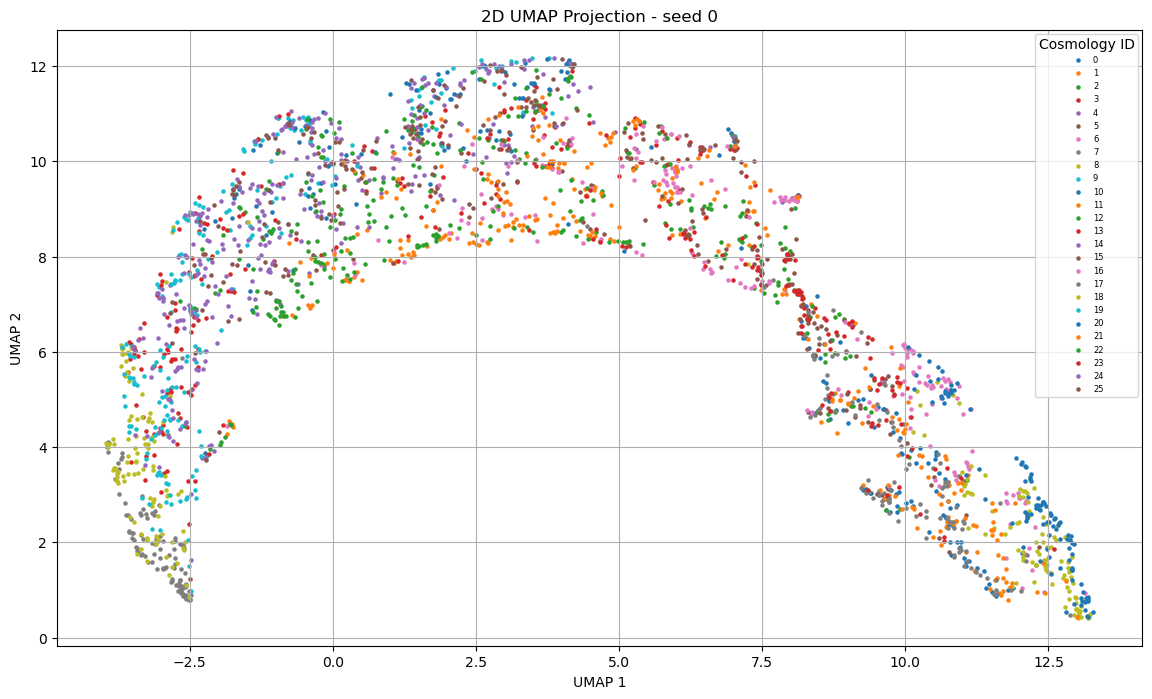

In [5]:
# 2D UMAP plot
plt.figure(figsize=(14, 8))
for i in range(26):
    plt.scatter(umap_embedding_2d[mask[i], 0], umap_embedding_2d[mask[i], 1], label=str(i), s=5)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection - seed '+str(rd_state))
plt.legend(title='Cosmology ID',loc=1, prop={'size': 6})
plt.grid(True)
plt.show()

TEST UMAP HYPERPARAMETERS

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


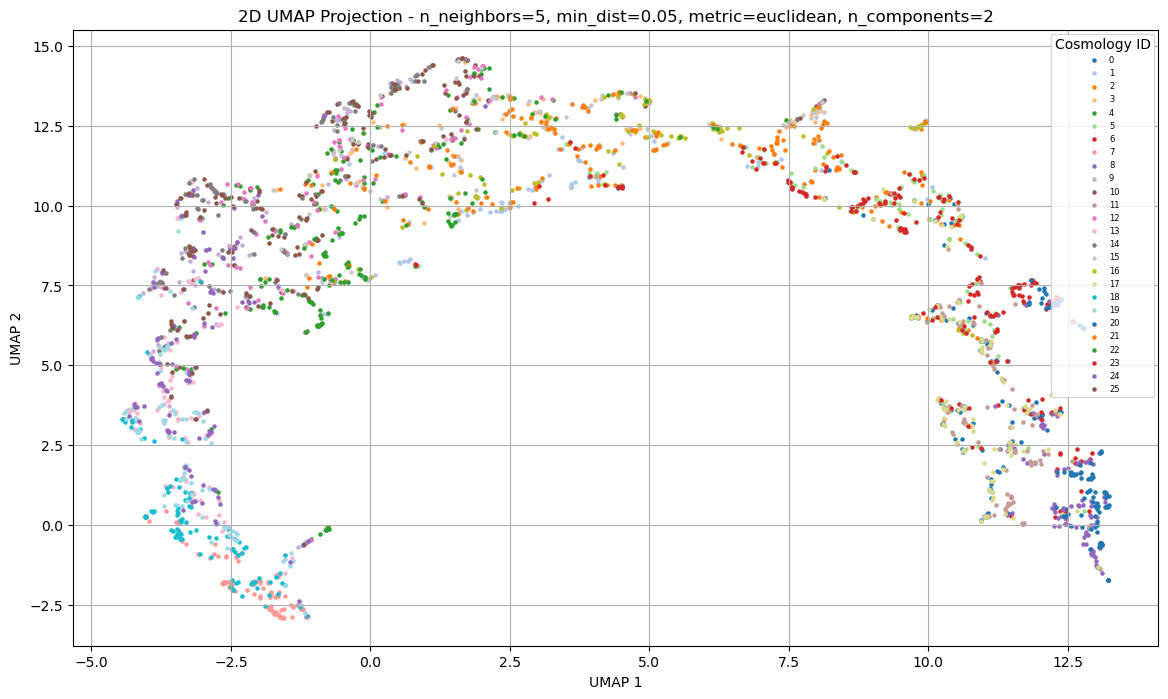

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


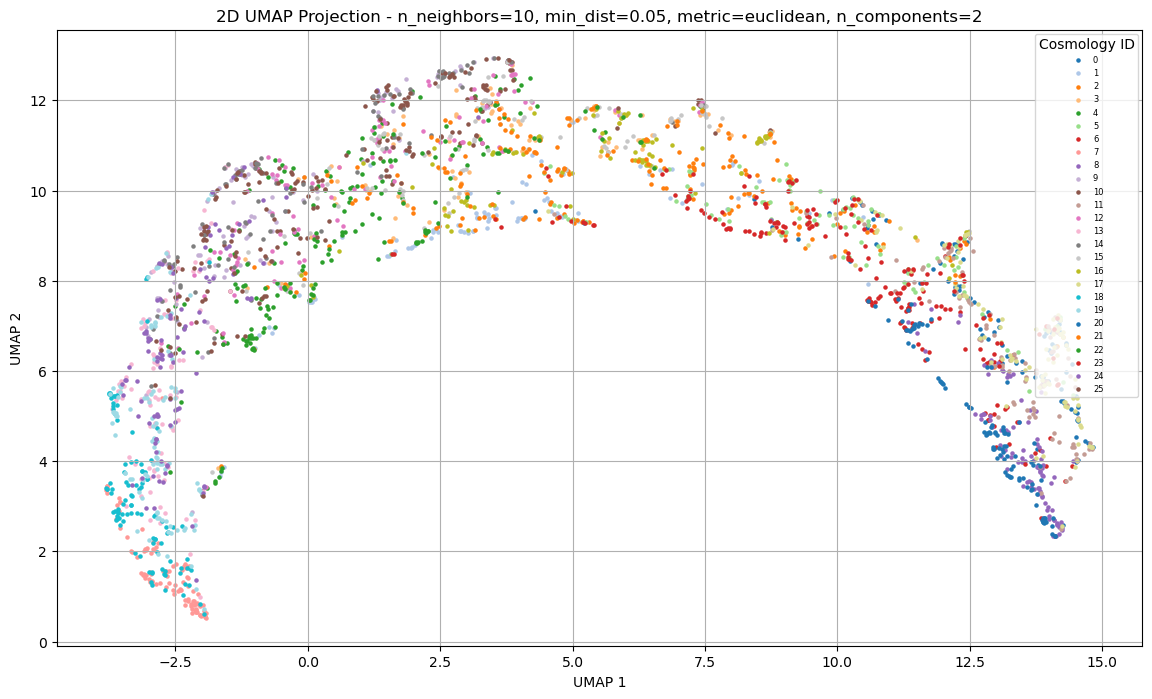

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


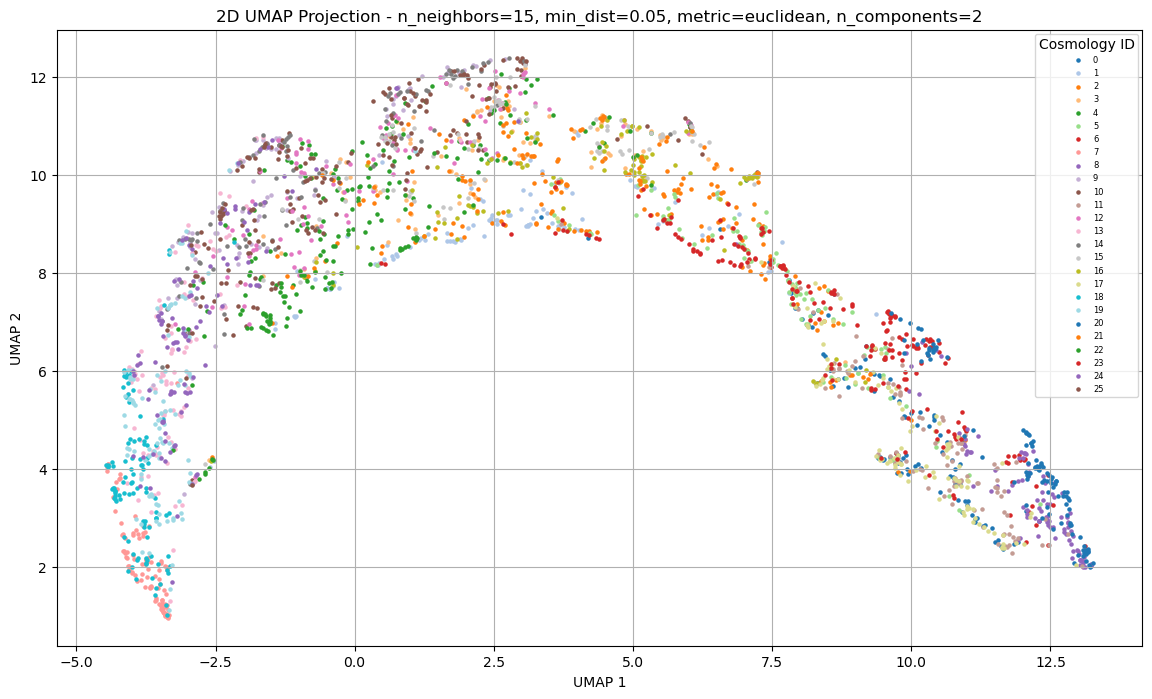

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


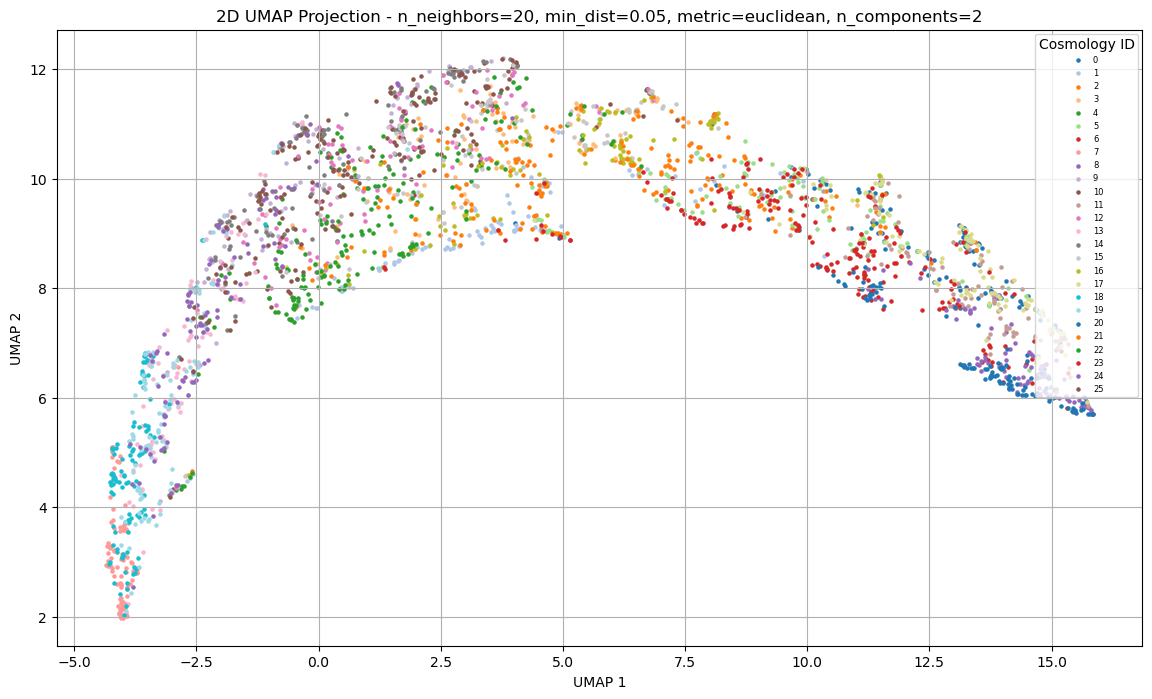

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


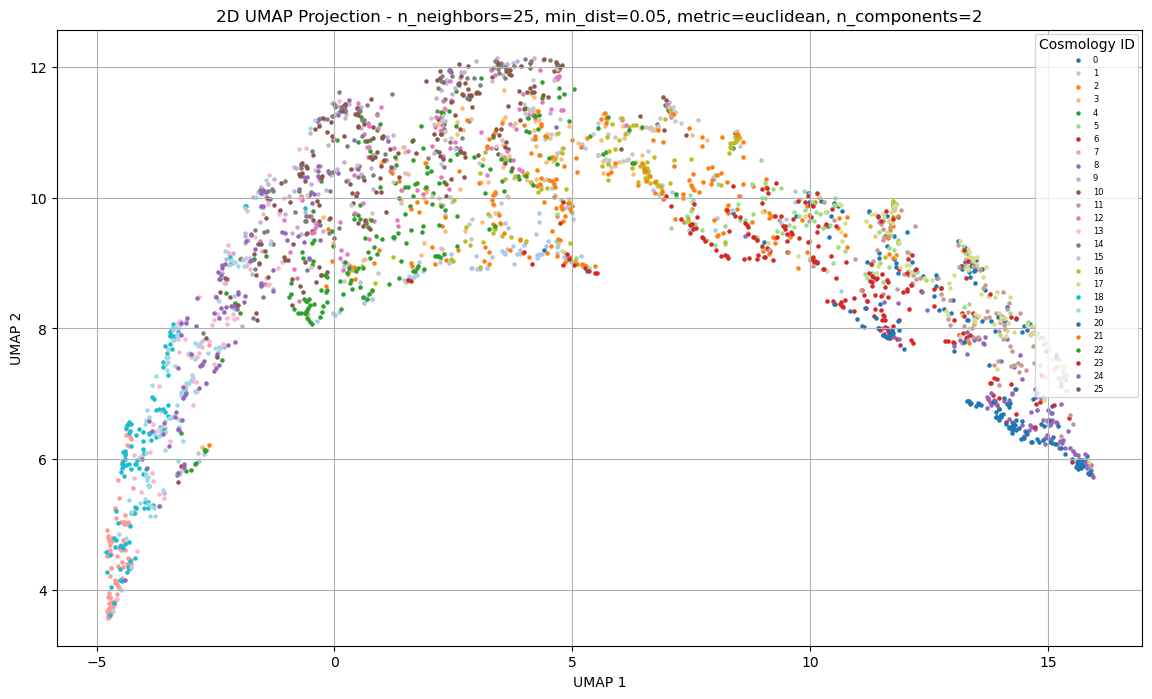

/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


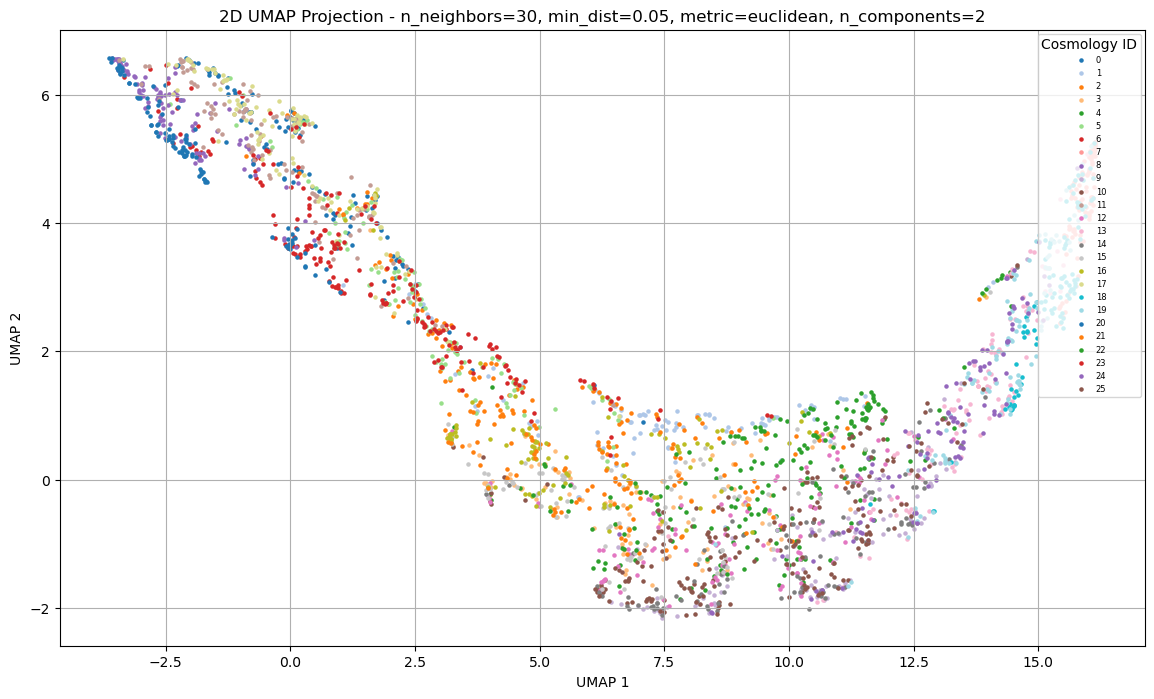

In [11]:
# List of hyperparameter configurations
hyperparameters = [
    {'n_neighbors':5, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0}
    {'n_neighbors':5, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
]

# Function to plot UMAP embedding
def plot_umap(embedding, title):
    plt.figure(figsize=(14, 8))
    colors = cycle(plt.get_cmap('tab20').colors + plt.get_cmap('tab10').colors[:6])
    color_map = {i: next(colors) for i in range(26)}
    
    for i in range(26):
        plt.scatter(embedding[mask[i], 0], embedding[mask[i], 1], label=str(i), s=5, color=color_map[i])
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.title(title)
    plt.legend(title='Cosmology ID', loc='upper right', prop={'size': 6})
    plt.grid(True)
    plt.show()

# Apply UMAP with different hyperparameters and plot the results
for params in hyperparameters:
    umap_model = umap.UMAP(n_neighbors=params['n_neighbors'], 
                           min_dist=params['min_dist'], 
                           metric=params['metric'],
                           n_components=params['n_components'], 
                           random_state=params['random_state'])
    umap_embedding = umap_model.fit_transform(measured_files)
    title = f"2D UMAP Projection - n_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}, metric={params['metric']}, n_components={params['n_components']}"
    plot_umap(umap_embedding, title)


NORMAL

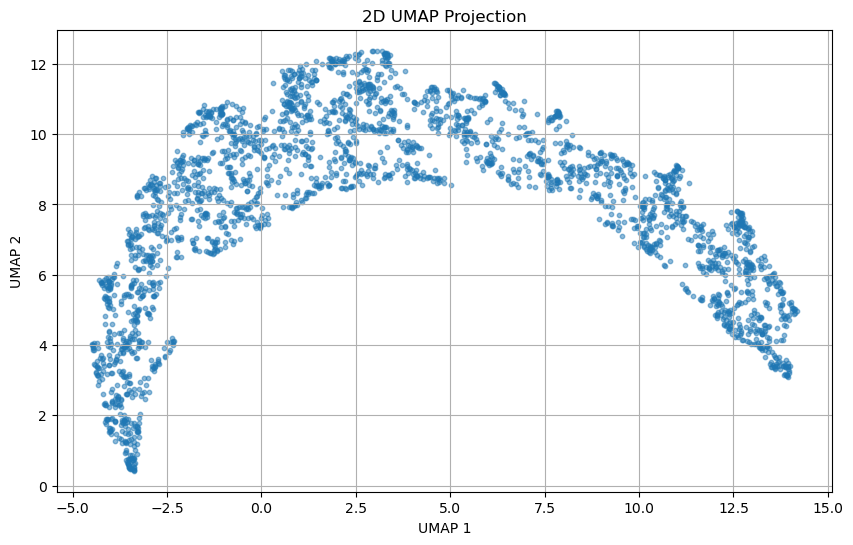

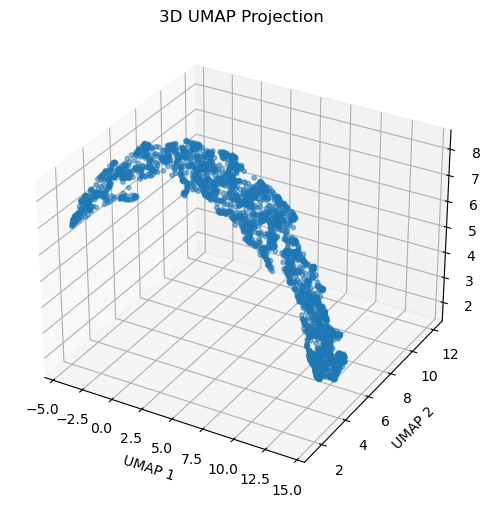

In [27]:
# 2D UMAP plot
plt.figure(figsize=(10, 6))
plt.scatter(umap_embedding_2d[:, 0], umap_embedding_2d[:, 1],s=10, alpha=0.5)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection')
plt.grid(True)
plt.show()

# 3D UMAP plot
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(umap_embedding_3d[:, 0], umap_embedding_3d[:, 1], umap_embedding_3d[:, 2], s=10, alpha=0.5)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_zlabel('UMAP 3')
ax.set_title('3D UMAP Projection')
plt.show()

UMAP THEORY

In [4]:
# Path to files
pcf_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/theory_2pcf'
param_file_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/lhs_26.csv'

# Load files
param_file_names = pd.read_csv(param_file_path)
pcf_files_names = glob.glob(f"{pcf_files_path}/id*2pcf.dat")
pcf_files_full = [np.loadtxt(file) for file in pcf_files_names]

# Create list of measured files, column 4 "xi"
pcf_files = []
for i in range(len(pcf_files_full)):
    data = pcf_files_full[i]
    row = [row[1] for row in data]
    pcf_files.append(row)

print("Seeds : ",seeds)
print("Shape param_files : ", np.shape(param_files))
print("Shape measured_files : ",np.shape(pcf_files))

Seeds :  [0]
Shape param_files :  (2704, 4)
Shape measured_files :  (26, 10)


In [7]:
# Apply UMAP
umap_2d_pcf = umap.UMAP(n_components=2)
umap_3d_pcf = umap.UMAP(n_components=3)

umap_embedding_2d_pcf = umap_2d_pcf.fit_transform(pcf_files)
umap_embedding_3d_pcf = umap_3d_pcf.fit_transform(pcf_files)

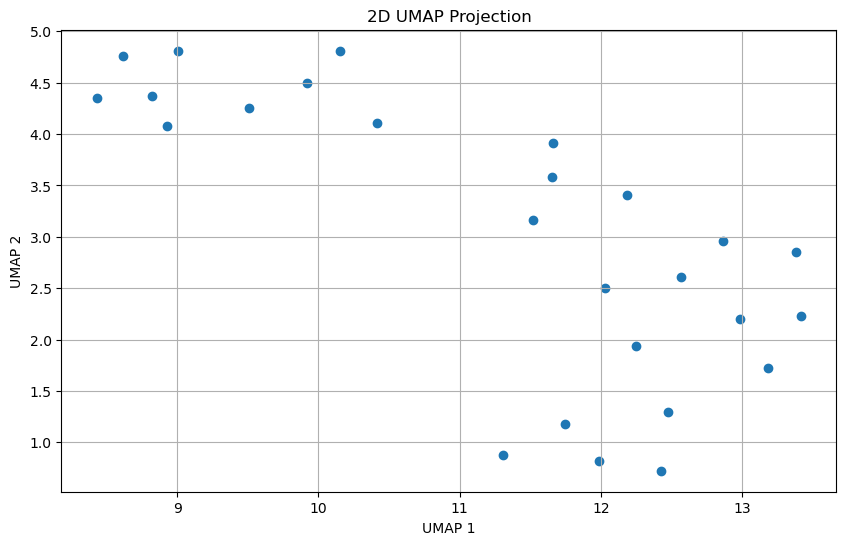

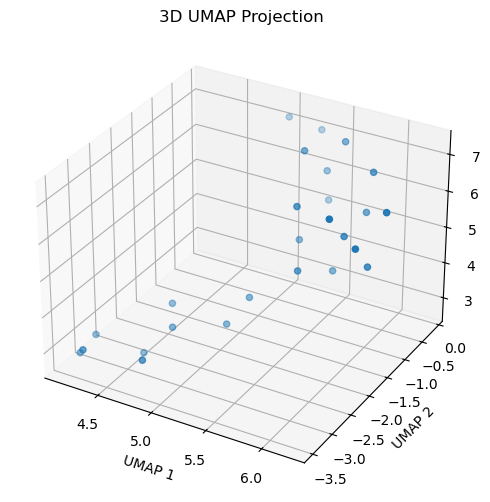

In [8]:
# 2D UMAP plot
plt.figure(figsize=(10, 6))
plt.scatter(umap_embedding_2d_pcf[:, 0], umap_embedding_2d_pcf[:, 1])
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection')
plt.grid(True)
plt.show()

# 3D UMAP plot
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(umap_embedding_3d_pcf[:, 0], umap_embedding_3d_pcf[:, 1], umap_embedding_3d_pcf[:, 2])
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_zlabel('UMAP 3')
ax.set_title('3D UMAP Projection')
plt.show()

UMAP THEORY + 0

In [18]:
pcf0_files = np.concatenate([pcf_files,measured_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(pcf_files) + [1]*len(measured_files))


# Apply UMAP
random_st = 1
umap_2d_pcf0 = umap.UMAP(n_components=2)
umap_3d_pcf0 = umap.UMAP(n_components=3)

umap_embedding_2d_pcf0 = umap_2d_pcf0.fit_transform(pcf0_files)
umap_embedding_3d_pcf0 = umap_3d_pcf0.fit_transform(pcf0_files)

# Create masks for the two groups
mask_pcf = labels == 0
mask_measured = labels == 1

# 2D UMAP plot
plt.figure(figsize=(10, 6))
plt.scatter(umap_embedding_2d_pcf0[mask_pcf, 0], umap_embedding_2d_pcf0[mask_pcf, 1], label='Theory')
plt.scatter(umap_embedding_2d_pcf0[mask_measured, 0], umap_embedding_2d_pcf0[mask_measured, 1], label='Measured', s=10, alpha=0.4)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection - seed '+str(random_st))
plt.legend()
plt.grid(True)
plt.show()

# 3D UMAP plot
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(umap_embedding_3d_pcf0[mask_pcf, 0], umap_embedding_3d_pcf0[mask_pcf, 1], umap_embedding_3d_pcf0[mask_pcf, 2], label='Theory')
ax.scatter(umap_embedding_3d_pcf0[mask_measured, 0], umap_embedding_3d_pcf0[mask_measured, 1], umap_embedding_3d_pcf0[mask_measured, 2], label='Measured',s=5, alpha=0.5)

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_zlabel('UMAP 3')
ax.set_title('3D UMAP Projection - seed')
ax.legend()
plt.show()

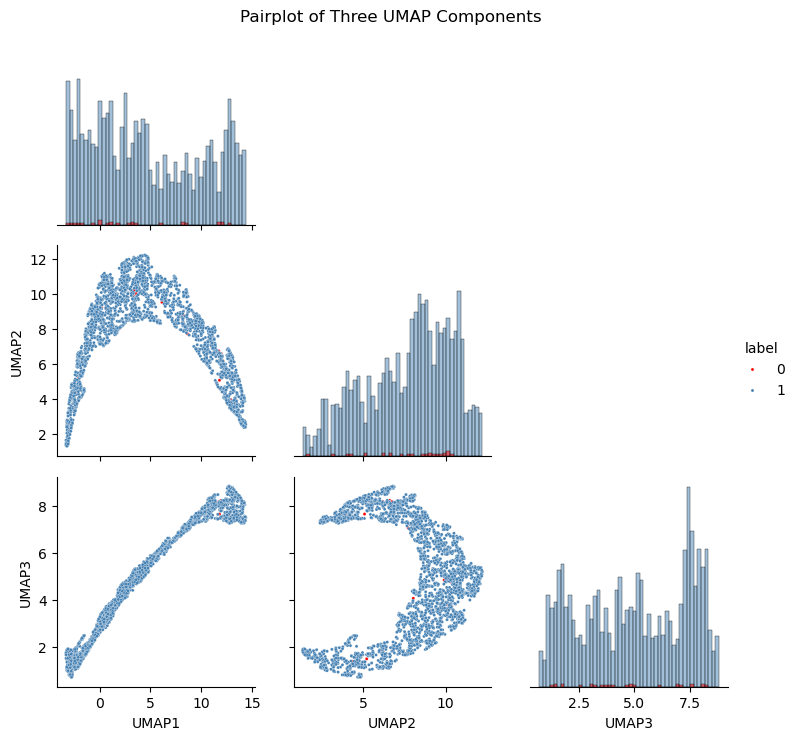

In [41]:
df_umap = pd.DataFrame(data=umap_embedding_3d_pcf0[:, :3], columns=['UMAP1', 'UMAP2', 'UMAP3'])
df_umap['label'] = labels

mask_pcf = labels == 0
mask_measured = labels == 1

# Custom PairGrid
g1 = sns.PairGrid(df_umap, hue='label', palette={0: "red", 1: "steelblue"}, corner=True)

g1 = g1.map_lower(sns.scatterplot, s=5, alpha=1)  # Smaller points in the lower triangle
g1 = g1.map_diag(sns.histplot, bins=50)  # Histogram on the diagonal


# Add legend
g1.add_legend()

plt.suptitle('Pairplot of Three UMAP Components')
plt.show()

In [42]:
# New points in 3D UMAP space
new_points = np.random.uniform(low=np.min(umap_embedding_3d_pcf0, axis=0),
                               high=np.max(umap_embedding_3d_pcf0, axis=0),
                               size=(24, umap_embedding_3d_pcf0.shape[1]))

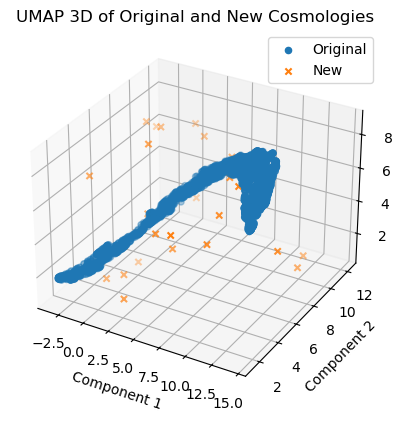

In [44]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(umap_embedding_3d_pcf0[:, 0], umap_embedding_3d_pcf0[:, 1], umap_embedding_3d_pcf0[:, 2], label='Original')
ax.scatter(new_points[:, 0], new_points[:, 1], new_points[:, 2], label='New', marker='x')
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_zlabel('Component 3')
ax.legend()
plt.title('UMAP 3D of Original and New Cosmologies')
plt.show()

UMAP cosmoslics + 26 + 1000

In [5]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import umap.umap_ as umap
import os
import matplotlib.pyplot as plt
import glob
from scipy.spatial import ConvexHull, Delaunay

In [8]:
# Path to files
dbb26_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26/theory_2pcf'
dbb26maximin_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_26maximin/theory_2pcf'
cosmoslics_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_COSMOSLICS/theory_2pcf'
dbb1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'


# Load files
dbb26_files_names = sorted(glob.glob(f"{dbb26_files_path}/id*2pcf.dat"))
dbb26_files_full = [np.loadtxt(file) for file in dbb26_files_names]
dbb26maximin_files_names = sorted(glob.glob(f"{dbb26maximin_files_path}/id*2pcf.dat"))
dbb26maximin_files_full = [np.loadtxt(file) for file in dbb26maximin_files_names]
cosmoslics_files_names = sorted(glob.glob(f"{cosmoslics_files_path}/id*2pcf.dat"))
cosmoslics_files_full = [np.loadtxt(file) for file in cosmoslics_files_names]
dbb1000_files_names = sorted(glob.glob(f"{dbb1000_files_path}/id*2pcf.dat"))
dbb1000_files_full = [np.loadtxt(file) for file in dbb1000_files_names]


# Create list of measured files
dbb26_files = []
for i in range(len(dbb26_files_full)):
   data = dbb26_files_full[i]
   row = [row[1] for row in data]
   dbb26_files.append(row)

dbb26maximin_files = []
for i in range(len(dbb26maximin_files_full)):
   data = dbb26maximin_files_full[i]
   row = [row[1] for row in data]
   dbb26maximin_files.append(row)


cosmoslics_files = []
for i in range(len(cosmoslics_files_full)):
   data = cosmoslics_files_full[i]
   row = [row[1] for row in data]
   cosmoslics_files.append(row)


dbb1000_files = []
for i in range(len(dbb1000_files_full)):
   data = dbb1000_files_full[i]
   row = [row[1] for row in data]
   dbb1000_files.append(row)


print("Shape dbb26 : ",np.shape(dbb26_files))
print("Shape dbb26maximin : ",np.shape(dbb26maximin_files))
print("Shape cosmoslics : ",np.shape(cosmoslics_files))
print("Shape dbb1000 : ",np.shape(dbb1000_files))

#########################################
full_files = np.concatenate([dbb26_files,cosmoslics_files,dbb1000_files,dbb26maximin_files])

# Create labels to distinguish theory from seed 0
labels = np.array(['LHS_26']*len(dbb26_files) + ['cosmo-SLICS']*len(cosmoslics_files) + ['LHS_1000']*len(dbb1000_files) + ['Maximin_26']*len(dbb26maximin_files))


#################################################
rd_state = 10
umap_2d_full = umap.UMAP(n_components=2, random_state=rd_state)
umap_3d_full = umap.UMAP(n_components=3, random_state=rd_state)

umap_embedding_2d_full = umap_2d_full.fit_transform(full_files)
umap_embedding_3d_full = umap_3d_full.fit_transform(full_files)

###################################################
# Create masks for the two groups
mask_26 = labels == 'LHS_26'
mask_cosmo = labels == 'cosmo-SLICS'
mask_1000 = labels == 'LHS_1000'
mask_26max = labels == 'Maximin_26'

# 2D UMAP plot
plt.figure(figsize=(10, 6))
plt.scatter(umap_embedding_2d_full[mask_26, 0], umap_embedding_2d_full[mask_26, 1], label='LHS_26',s=15, color="blue")
plt.scatter(umap_embedding_2d_full[mask_1000, 0], umap_embedding_2d_full[mask_1000, 1], label='LHS_1000',color="green", s=10, alpha=0.3)
plt.scatter(umap_embedding_2d_full[mask_cosmo, 0], umap_embedding_2d_full[mask_cosmo, 1], label='cosmo-SLICS',color="red",s=15)
plt.scatter(umap_embedding_2d_full[mask_26max, 0], umap_embedding_2d_full[mask_26max, 1], label='Maximin_26',color="orange",s=15)

plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection - seed '+str(rd_state))
plt.legend()
plt.grid(True)
plt.show()
############################################
# SNS

df_full = pd.DataFrame(data=umap_embedding_3d_full[:, :3], columns=['UMAP1', 'UMAP2', 'UMAP3'])
df_full['label'] = labels

# Custom PairGrid
g2 = sns.PairGrid(df_full, hue='label', palette={'LHS_26': "blue", 'cosmo-SLICS': 'red', 'LHS_1000': "lightgreen"}, corner=True)

g2 = g2.map_lower(sns.scatterplot, s=5, alpha=1)  # Smaller points in the lower triangle
g2 = g2.map_diag(sns.histplot, bins=50)  # Histogram on the diagonal

# Add legend
g2.add_legend()

plt.suptitle('Pairplot of Three UMAP Components - seed '+str(rd_state))
plt.show()

Shape dbb26 :  (26, 10)
Shape dbb26maximin :  (26, 10)
Shape cosmoslics :  (25, 10)
Shape dbb1000 :  (999, 10)


In [ ]:
# List of hyperparameter configurations
hyperparameters = [
    {'n_neighbors':2, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.05, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':2, 'min_dist':0.01, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.1, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.2, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':5, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':10, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
    {'n_neighbors':15, 'min_dist':0.3, 'metric':'euclidean', 'n_components':2, 'random_state': 0},
]

# Function to plot UMAP embedding
def plot_umap(embedding, title):
    plt.figure(figsize=(14, 8))
    plt.scatter(embedding[mask_26, 0], embedding[mask_26, 1], label='LHS_26',s=15, color="blue")
    plt.scatter(embedding[mask_1000, 0], embedding[mask_1000, 1], label='LHS_1000',color="green", s=10, alpha=0.3)
    plt.scatter(embedding[mask_cosmo, 0], embedding[mask_cosmo, 1], label='cosmo-SLICS',color="red",s=15)
    plt.xlabel('UMAP 1')
    plt.ylabel('UMAP 2')
    plt.title(title)
    plt.legend(title='Cosmology ID', loc='upper right', prop={'size': 6})
    plt.grid(True)
    plt.show()

# Apply UMAP with different hyperparameters and plot the results
for params in hyperparameters:
    umap_2d_full = umap.UMAP(n_neighbors=params['n_neighbors'], 
                           min_dist=params['min_dist'], 
                           metric=params['metric'],
                           n_components=params['n_components'], 
                           random_state=params['random_state'])
    umap_embedding_2d = umap_2d_full.fit_transform(full_files)
    title = f"2D UMAP Projection - n_neighbors={params['n_neighbors']}, min_dist={params['min_dist']}, metric={params['metric']}, n_components={params['n_components']}"
    plot_umap(umap_embedding_2d, title)

PLOT COLORMAPS

Shape l2000 :  (2000, 10)


/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


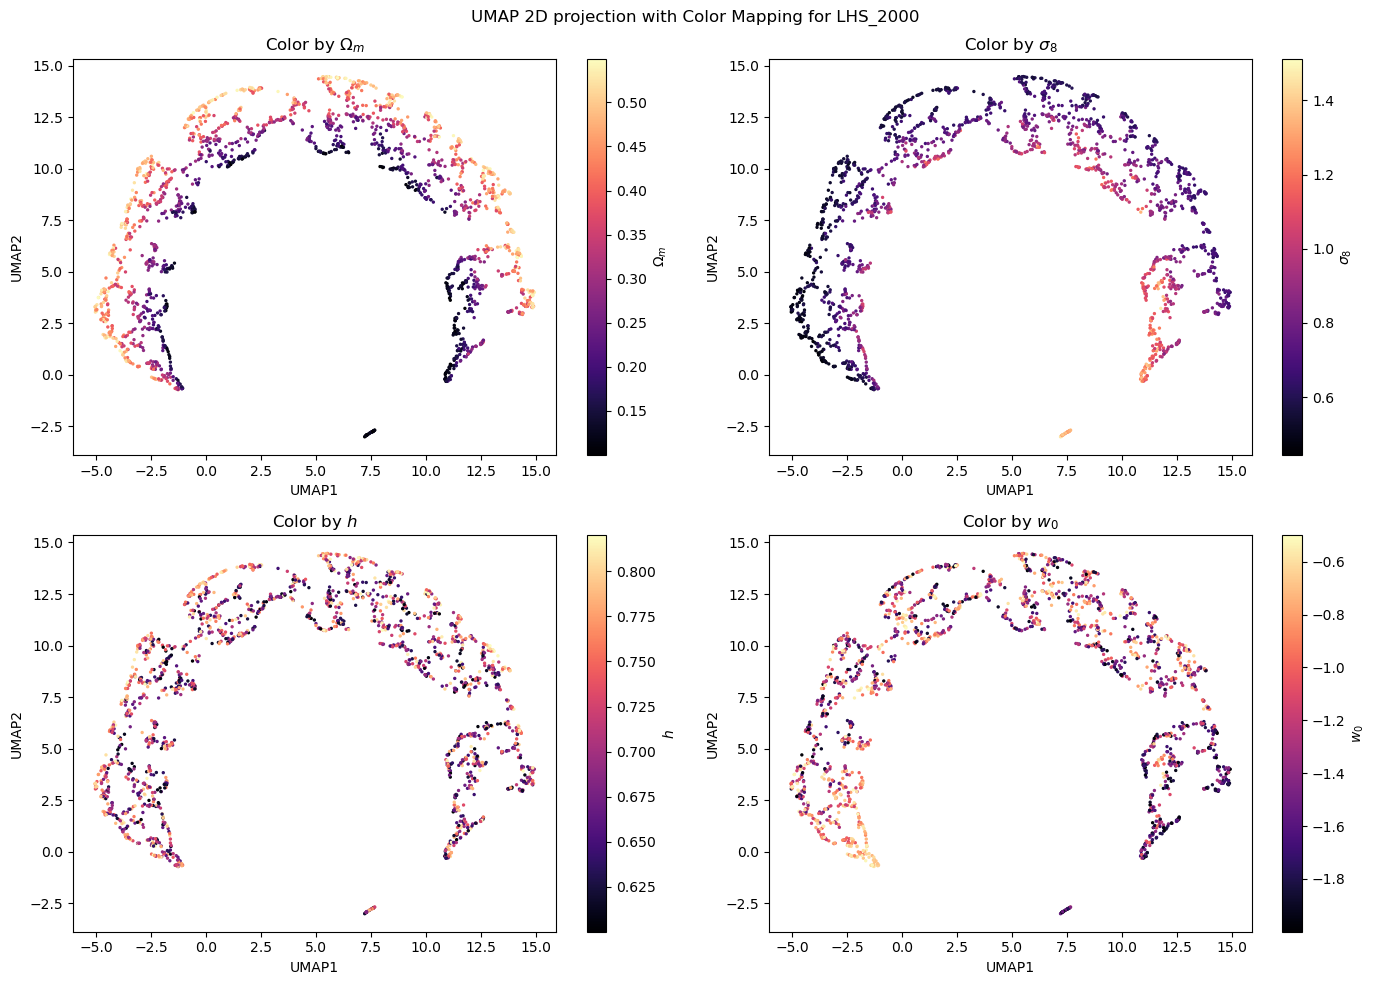

In [3]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$\sigma_8$','$h$','$w_0$']
Om = params['Om']
S8 = params['sig8']
h = params['h']
w0 = params['w0']
params_values = [Om,S8,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))

######################
# UMAP

rd_state = 0
umap_2d_full = umap.UMAP(n_components=2, random_state=rd_state)

umap_embedding_2d_full = umap_2d_full.fit_transform(l2000_files)


######################
# PLOTS


# 2D UMAP plot
# Create subplots
fig, axs = plt.subplots(2, 2, figsize=(14, 10))

# Plot each subplot
for i, ax in enumerate(axs.flat):
    scatter = ax.scatter(umap_embedding_2d_full[:, 0], umap_embedding_2d_full[:, 1], 
                         c=params_values[i], s=2, alpha=1, cmap='magma')
    ax.set_xlabel(f'UMAP1')
    ax.set_ylabel(f'UMAP2')
    ax.set_title(f'Color by {params_list[i]}')
    cbar = plt.colorbar(scatter, ax=ax)
    cbar.set_label(params_list[i])

plt.suptitle('UMAP 2D projection with Color Mapping for LHS_2000')
plt.tight_layout()
plt.show()

Shape dbb1000 :  (999, 10)


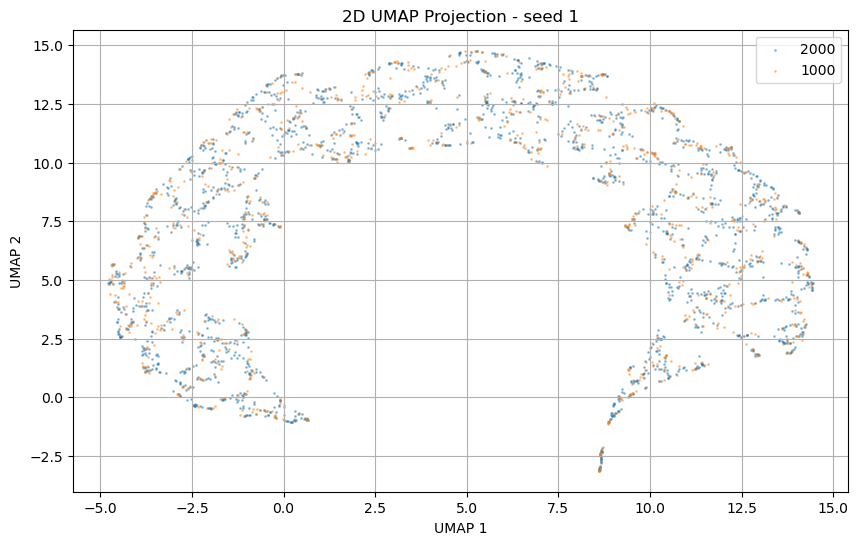

In [7]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/lhs_2000/lhs_2000_0.csv"
dbb1000_files_path = '/net/GECO/pisco/SHEAR2COSMO/DBB_OPT_1000/theory_2pcf'

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]
dbb1000_files_names = sorted(glob.glob(f"{dbb1000_files_path}/id*2pcf.dat"))
dbb1000_files_full = [np.loadtxt(file) for file in dbb1000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$S_8$','$h$','$w_0$']
Om = params['Om']
S8 = params['S8']
h = params['h']
w0 = params['w0']
params_values = [Om,S8,h,w0]

l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)


dbb1000_files = []
for i in range(len(dbb1000_files_full)):
   data = dbb1000_files_full[i]
   row = [row[1] for row in data]
   dbb1000_files.append(row)


print("Shape dbb1000 : ",np.shape(dbb1000_files))


pcf0_files = np.concatenate([l2000_files,dbb1000_files])

# Create labels to distinguish theory from seed 0
labels = np.array([0]*len(l2000_files) + [1]*len(dbb1000_files))


# Apply UMAP
random_st = 1
umap_2d_pcf0 = umap.UMAP(n_components=2)

umap_embedding_2d_pcf0 = umap_2d_pcf0.fit_transform(pcf0_files)

# Create masks for the two groups
mask_2000 = labels == 0
mask_1000 = labels == 1

# 2D UMAP plot
plt.figure(figsize=(10, 6))
plt.scatter(umap_embedding_2d_pcf0[mask_2000, 0], umap_embedding_2d_pcf0[mask_2000, 1], label='2000', s=2, alpha=0.8)
plt.scatter(umap_embedding_2d_pcf0[mask_1000, 0], umap_embedding_2d_pcf0[mask_1000, 1], label='1000', s=2, alpha=0.8)
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection - seed '+str(random_st))
plt.legend()
plt.grid(True)
plt.show()

Shape l2000 :  (2000, 10)


/net/CLUSTER/VAULT/users/lburon/micromamba/envs/SHEAR2COSMO/lib/python3.11/site-packages/umap/umap_.py:1943: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


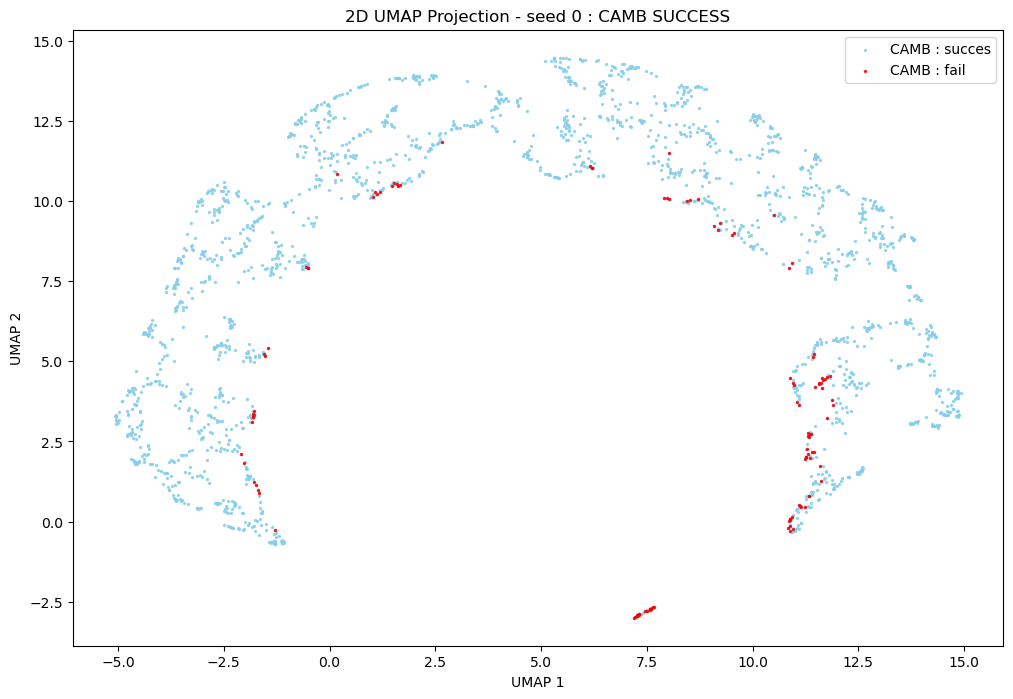

In [8]:
# Path to files
l2000_files_path = '/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/theory_2pcf/lhs_2000_0'
param_path = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/LHS_comparison/camb_test/lhs_2000/lhs_2000_0_camb.csv"

# Load files
l2000_files_names = sorted(glob.glob(f"{l2000_files_path}/id*2pcf.dat"))
l2000_files_full = [np.loadtxt(file) for file in l2000_files_names]

# Parameters
params = pd.read_csv(param_path)
params_list = ['$\Omega_m$','$S_8$','$h$','$w_0$']
camb_res = params['camb_res']
params_crash = params[params['camb_res']==0]
params_crash = params_crash.iloc[:,0]


l2000_files = []
for i in range(len(l2000_files_full)):
   data = l2000_files_full[i]
   row = [row[1] for row in data]
   l2000_files.append(row)

print("Shape l2000 : ",np.shape(l2000_files))


###############################################

# Apply UMAP
random_st = 0
umap_2d = umap.UMAP(n_components=2, random_state=random_st)

umap_embedding_2d = umap_2d.fit_transform(l2000_files)

# 2D UMAP plot
plt.figure(figsize=(12, 8))
plt.scatter(umap_embedding_2d[:, 0], umap_embedding_2d[:, 1], label='CAMB : succes', s=2, alpha=0.8, color='skyblue')
plt.scatter(umap_embedding_2d[params_crash, 0], umap_embedding_2d[params_crash, 1], label='CAMB : fail', s=2, alpha=0.8, color='red')
plt.xlabel('UMAP 1')
plt.ylabel('UMAP 2')
plt.title('2D UMAP Projection - seed '+str(random_st)+' : CAMB SUCCESS')
plt.legend()
plt.show()